# Regression_Classification_Model_Evaluation


In [1]:
%pip install pandas scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.0


In [3]:
from sklearn.impute import SimpleImputer
import numpy as np

data = np.array([
    [10],
    [20],
    [np.nan],
    [40],
    [50]
])

imputer = SimpleImputer(strategy="mean")
cleaned_data = imputer.fit_transform(data)

print(cleaned_data)

[[10.]
 [20.]
 [30.]
 [40.]
 [50.]]


In [5]:
from sklearn.model_selection import train_test_split
import pandas as pd

data = {
    "Hours_Studied": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks": [20, 25, 35, 40, 50, 55, 65, 75, 85, 95]
}

df = pd.DataFrame(data)

X = df[["Hours_Studied"]]
y = df["Marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 8
Testing rows: 2


In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

predicted_marks = model.predict([[7.5]])

print("Predicted Marks:", predicted_marks[0])

Predicted Marks: 70.8405172413793


C:\Users\Mahaveer\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [7]:
model.predict(pd.DataFrame({"Hours_Studied": [7.5]}))

array([70.84051724])

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

print("Actual Marks:", list(y_test))
print("Predicted Marks:", y_pred.round(2))

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

Actual Marks: [85, 25]
Predicted Marks: [83.19 25.56]
MAE: 1.1853448275862135
MSE: 1.7956673602853992
RMSE: 1.3400251341991312
R2 Score: 0.9980048140441273


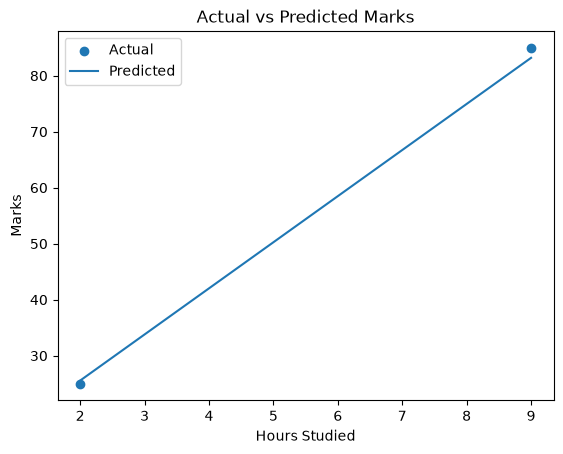

In [9]:
import matplotlib.pyplot as plt

plt.scatter(X_test["Hours_Studied"], y_test, label="Actual")
plt.plot(X_test["Hours_Studied"], y_pred, label="Predicted")

plt.xlabel("Hours Studied")
plt.ylabel("Marks")
plt.title("Actual vs Predicted Marks")
plt.legend()
plt.show()

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = {
    "Hours_Studied": [1, 2, 2, 3, 4, 5, 6, 7, 8, 9],
    "Passed":        [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
}

df = pd.DataFrame(data)

X = df[["Hours_Studied"]]
y = df["Passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Predictions:", y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Predictions: [0 0 1]
Accuracy: 1.0
Confusion Matrix:
 [[2 0]
 [0 1]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3

